# 03 · A bead in a free-space tweezer: stochastic simulation against theory

The `levisim.data` and `levisim.analysis` packages simulate a single silica bead in a free-space
optical tweezer - classical Langevin dynamics with gas damping, feedback cold damping and a
*directed* stochastic force - and analyse the traces like experimental data. This notebook runs a
seeded simulation, then checks it against `SpectralDensityTheory` and equipartition: the effective
temperature, the position spectra, the $x$-$y$ cross spectrum that the directed force creates, and
the detection floor.

**Runtime:** about 20 s (two simulations of 2 × 10⁵ steps). **Background:**
[Stochastic simulations of a bead in a free-space tweezer](../../docs/guide/stochastic_simulations.md),
whose worked example makes the same checks on a run twice as long.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from levisim.analysis.spectral_density_estimate import SpectralDensityEstimate
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import Hz, kHz, nm, μs, degrees
from levisim.data.simulation import Simulation
from levisim.physics.trap import Trap

set_plt_rcParams_to_xmgrace_style()

## 1. The trap

`Trap()` combines a `Tweezer` (485 mW at 1064 nm), a `Bead` (radius 60.1 nm) and a `Gas`
($4\times10^{-3}$ mbar, 300 K), and adds feedback cold damping in $x$ and $y$ and a directed white
force of strength $\beta f_\text{th}$ ($\beta = \sqrt2$) along the angle $\psi = 45^\circ$ in the
$x$-$y$ plane. Cold damping lowers the temperature, $T_{\text{eff},j} = T\,\Gamma_\text{th}/(\Gamma_\text{th} + \Gamma_{\text{fb},j})$,
and the directed force raises it again by the factor $1 + S_{\text{dir},j}/S_\text{th}$.

In [ ]:
trap = Trap()
print(f'Ω/2π: x {trap.Ωx / kHz:.2f}, y {trap.Ωy / kHz:.2f}, z {trap.Ωz / kHz:.2f} kHz')
print(f'Γ_th/2π = {trap.Γth / Hz:.3f} Hz; Γ_x/2π = {trap.Γx / kHz:.4f} kHz, Γ_y/2π = {trap.Γy / kHz:.4f} kHz (gas + feedback)')
print(f'directed force: β = {trap.β:.4f}, ψ = {trap.ψ / degrees:.0f}°')
print(f'T_eff: x {trap.T_eff["x"]:.3f} K, y {trap.T_eff["y"]:.3f} K'
      f' (without the directed force: x {300 * trap.Γth / trap.Γx:.3f} K, y {300 * trap.Γth / trap.Γy:.3f} K)')

Ω/2π: x 156.34, y 135.80, z 35.06 kHz
Γ_th/2π = 4.332 Hz; Γ_x/2π = 2.1043 kHz, Γ_y/2π = 2.5043 kHz (gas + feedback)
directed force: β = 1.4142, ψ = 45°
T_eff: x 1.235 K, y 1.038 K (without the directed force: x 0.618 K, y 0.519 K)


## 2. Simulate

Kasdin's stochastic fourth-order Runge-Kutta scheme, 2 × 10⁵ steps of $\Delta t = 0.1\ \mu$s (20 ms,
Nyquist frequency 5 MHz). `seed` makes the run reproducible. `detection_floor` adds white
measurement noise of one-sided PSD $10^{-27}$ m²/Hz to the *recorded* traces only; the integrated
state `sim.X` never sees it.

simulated 200000 steps (20 ms of motion)


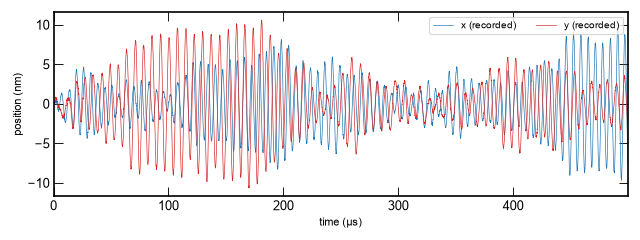

In [ ]:
G_floor = 1e-27   # one-sided detection floor [m²/Hz]
sim = Simulation(trap=trap, num_samples=200_000, Δt=0.1 * μs, seed=2026, detection_floor=G_floor)
print(f'simulated {sim.num_samples} steps ({sim.time_length * 1e3:.0f} ms of motion)')

fig, ax = plt.subplots(figsize=(8, 3))
t = np.arange(5000) * sim.Δt / μs
ax.plot(t, sim.x.values[:5000] / nm, lw=0.6, color='tab:blue', label='x (recorded)')
ax.plot(t, sim.y.values[:5000] / nm, lw=0.6, color='tab:red', label='y (recorded)')
ax.set_xlim(t[0], t[-1])
ax.set_xlabel('time (μs)')
ax.set_ylabel('position (nm)')
ax.legend(fontsize=9, loc='upper right', ncols=2)
fig.tight_layout()

The first half-millisecond. The bead starts at rest, reaches its thermal amplitude within the
damping time $1/\Gamma_x \approx 76\ \mu$s, and its envelope then wanders on that timescale.

## 3. Equipartition

$T = m\Omega_j^2\,\mathrm{Var}(j)/k_B$, with the floor's variance $G_\text{floor}/2\Delta t$ removed. A run of
length $T_\text{run}$ estimates a variance with relative standard error $\approx\sqrt{2/(\Gamma_j T_\text{run})}$.

In [ ]:
floor_variance = G_floor / (2 * sim.Δt)
for axis in ('x', 'y'):
    T_variance = trap.equipartition_factor[axis] * (np.var(sim.traces[axis].values) - floor_variance)
    T_state = trap.equipartition_factor[axis] * np.var(sim.X[:, 'xyz'.index(axis)])   # no floor at all
    error = np.sqrt(2 / (trap.Γj[axis] * sim.time_length))
    print(f'{axis}: T_eff = {trap.T_eff[axis]:.3f} K | recorded, floor removed: {T_variance:.3f} K'
          f' | integrated state: {T_state:.3f} K | expected scatter ±{100 * error:.1f}%'
          f' -> deviation {(T_variance / trap.T_eff[axis] - 1) / error:+.1f} σ')

x: T_eff = 1.235 K | recorded, floor removed: 1.114 K | integrated state: 1.114 K | expected scatter ±8.7% -> deviation -1.1 σ
y: T_eff = 1.038 K | recorded, floor removed: 0.930 K | integrated state: 0.930 K | expected scatter ±8.0% -> deviation -1.3 σ


Both temperatures are consistent with $T_\text{eff}$ given the single-run scatter (deviations of
about one standard deviation), and the integrated state gives the same value as the recorded trace
with the floor's variance subtracted: the floor is pure measurement noise.

## 4. Position spectra

`SpectralDensityEstimate` averages periodograms of `num_segments` segments (Bartlett's method; here
20 segments, so 1 kHz bins with a 22% error each) and is one-sided by default, like the theory
`trap.theory` (a `SpectralDensityTheory`). Fitting the Lorentzian gives a second temperature, and
the fitted frequency and linewidth.

x: T via fit 0.995 K, Ω_fit/Ω = 0.9984, Γ_fit/Γ = 1.000
y: T via fit 0.957 K, Ω_fit/Ω = 0.9966, Γ_fit/Γ = 1.487


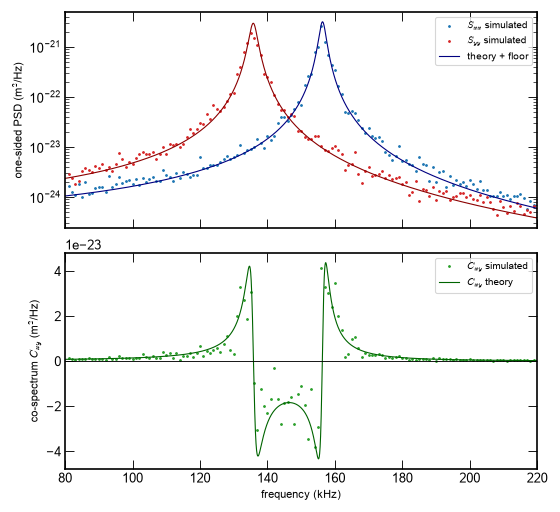

In [ ]:
Sxx = SpectralDensityEstimate(sim, 'xx', num_segments=20)
Syy = SpectralDensityEstimate(sim, 'yy', num_segments=20)
Sxy = SpectralDensityEstimate(sim, 'xy', num_segments=20)
theory = trap.theory

for axis, estimate in (('x', Sxx), ('y', Syy)):
    print(f'{axis}: T via fit {estimate.temperature_via_fit:.3f} K, Ω_fit/Ω = {estimate.Ωfit / trap.Ωj[axis]:.4f},'
          f' Γ_fit/Γ = {estimate.Γfit / trap.Γj[axis]:.3f}')

f = Sxx.freq_range
sel = (f > 80e3) & (f < 220e3)
f_fine = np.linspace(80e3, 220e3, 4000)   # theory on a fine grid, estimates on their 1 kHz bins
ω = 2 * np.pi * f_fine
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6.4), sharex=True)
ax1.semilogy(f[sel] / 1e3, np.real(Sxx.values[sel]), '.', ms=3, color='tab:blue', label=r'$S_{xx}$ simulated')
ax1.semilogy(f[sel] / 1e3, np.real(Syy.values[sel]), '.', ms=3, color='tab:red', label=r'$S_{yy}$ simulated')
ax1.semilogy(f_fine / 1e3, theory.Sxx(ω) + G_floor, color='navy', label='theory + floor')
ax1.semilogy(f_fine / 1e3, theory.Syy(ω) + G_floor, color='darkred')
ax1.set_ylabel(r'one-sided PSD (m$^2$/Hz)')
ax1.legend(fontsize=9, loc='upper right')
ax2.plot(f[sel] / 1e3, np.real(Sxy.values[sel]), '.', ms=3, color='tab:green', label=r'$C_{xy}$ simulated')
ax2.plot(f_fine / 1e3, theory.Cxy(ω), color='darkgreen', label=r'$C_{xy}$ theory')
ax2.axhline(0, color='k', lw=0.8)
ax2.set_xlim(f_fine[0] / 1e3, f_fine[-1] / 1e3)
ax2.set_xlabel('frequency (kHz)')
ax2.set_ylabel(r'co-spectrum $C_{xy}$ (m$^2$/Hz)')
ax2.legend(fontsize=9, loc='upper right')
fig.tight_layout()

## 5. The directed force correlates $x$ and $y$

The thermal forces on $x$ and $y$ are independent, but the directed force pushes both with the same
noise, so it correlates them: $S_{xy}(\omega) = \chi_x^*(\omega)\chi_y(\omega)\,S_\text{dir}\cos\psi\sin\psi$.
Its real part, the co-spectrum $C_{xy}$ above, changes sign between the two resonances, where the
phases of $\chi_x$ and $\chi_y$ differ by up to $\pi$; outside them its sign follows $\sin 2\psi$. So
the cross spectrum carries the direction of the force. Turning the force to $\psi = -45^\circ$
should flip the co-spectrum, and leave $S_{xx}$ and $S_{yy}$ unchanged:

In [ ]:
trap_flipped = Trap(ψ=-45 * degrees)
sim_flipped = Simulation(trap=trap_flipped, num_samples=200_000, Δt=0.1 * μs, seed=7, detection_floor=G_floor)
Sxy_flipped = SpectralDensityEstimate(sim_flipped, 'xy', num_segments=20)

# compare the measured co-spectra with theory in three bands: below, between and above the peaks
for name, simulation, estimate, model in (('ψ = +45°', sim, Sxy, theory), ('ψ = -45°', sim_flipped, Sxy_flipped, trap_flipped.theory)):
    fb = estimate.freq_range
    cells = []
    for lo, hi in ((90e3, 125e3), (138e3, 154e3), (165e3, 220e3)):
        band = (fb > lo) & (fb < hi)
        cells.append(f'{np.mean(np.real(estimate.values[band])):+.2e} ({np.mean(model.Cxy(2 * np.pi * fb[band])):+.2e})')
    # Cov(x, y) = ∫C_xy df; a run of length T estimates it with variance (1/T)∫(G_xx·G_yy + |G_xy|²)/2 df
    ff = np.linspace(1, simulation.Nyquist_frequency, 1_000_001)
    ωf = 2 * np.pi * ff
    cov_theory = np.trapezoid(model.Cxy(ωf), ff)
    cov_scatter = np.sqrt(np.trapezoid((model.Sxx(ωf) * model.Syy(ωf) + np.abs(model.Sxy(ωf))**2) / 2, ff) / simulation.time_length)
    cov = np.cov(simulation.x.values, simulation.y.values)[0, 1]
    print(f'{name}: mean C_xy simulated (theory) below / between / above: ' + ' | '.join(cells))
    print(f'          Cov(x, y) simulated {cov / nm**2:+.4f} nm², theory {cov_theory / nm**2:+.4f} ± {cov_scatter / nm**2:.4f} nm²'
          f' (one run) -> deviation {(cov - cov_theory) / cov_scatter:+.1f} σ')

ψ = +45°: mean C_xy simulated (theory) below / between / above: +2.27e-24 (+2.43e-24) | -1.87e-23 (-2.25e-23) | +1.27e-24 (+1.31e-24)
          Cov(x, y) simulated +0.1773 nm², theory +0.0683 ± 0.0809 nm² (one run) -> deviation +1.3 σ
ψ = -45°: mean C_xy simulated (theory) below / between / above: -2.74e-24 (-2.43e-24) | +2.47e-23 (+2.25e-23) | -1.25e-24 (-1.31e-24)
          Cov(x, y) simulated -0.0120 nm², theory -0.0683 ± 0.0809 nm² (one run) -> deviation +0.7 σ


The co-spectrum flips sign in every band, as the theory says. The covariance $\mathrm{Cov}(x, y)$
is the integral of $C_{xy}$. It is tiny - a correlation coefficient below 1%, against variances of
about 10 nm² - because the positive and negative lobes nearly cancel when $\Omega_x \ne \Omega_y$,
so a single run measures it only to about its own size, and both runs deviate from theory by about
one standard deviation. The spectrum resolves what the covariance hides.

## 6. Far from resonance: the detection floor

Away from the resonances the motion's PSD falls as $\omega^{-4}$ until it meets the floor. A
rectangular window leaks the resonance into that tail; a Blackman-Harris window (normalised to
unit mean square, so broadband levels are preserved) does not:

0.3-0.5 MHz: mean S_xx / (theory + floor) = 1.417 (rectangular), 0.986 (Blackman-Harris)
1.0-4.5 MHz: mean S_xx / (theory + floor) = 1.276 (rectangular), 1.005 (Blackman-Harris)


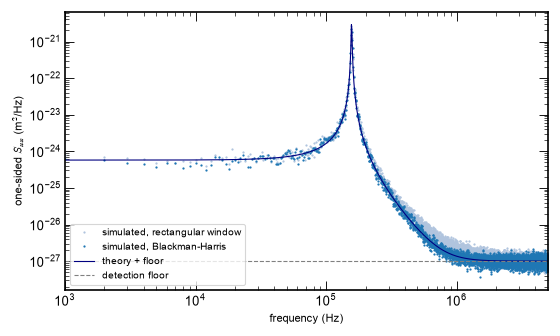

In [ ]:
Sxx_bh = SpectralDensityEstimate(sim, 'xx', num_segments=20, window='blackmanharris')
wide = (f > 0) & (f < sim.Nyquist_frequency)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(f[wide], np.real(Sxx.values[wide]), '.', ms=2, color='lightsteelblue', label='simulated, rectangular window')
ax.loglog(f[wide], np.real(Sxx_bh.values[wide]), '.', ms=2, color='tab:blue', label='simulated, Blackman-Harris')
ax.loglog(f[wide], theory.Sxx(2 * np.pi * f[wide]) + G_floor, color='navy', label='theory + floor')
ax.axhline(G_floor, ls='--', color='grey', lw=1, label='detection floor')
ax.set_xlim(f[wide][0], f[wide][-1])
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel(r'one-sided $S_{xx}$ (m$^2$/Hz)')
ax.legend(fontsize=9, loc='lower left')
fig.tight_layout()
for lo, hi in ((0.3e6, 0.5e6), (1e6, 4.5e6)):
    band = (f > lo) & (f < hi)
    model = np.mean(theory.Sxx(2 * np.pi * f[band]) + G_floor)
    print(f'{lo / 1e6}-{hi / 1e6} MHz: mean S_xx / (theory + floor) = {np.mean(np.real(Sxx.values[band])) / model:.3f}'
          f' (rectangular), {np.mean(np.real(Sxx_bh.values[band])) / model:.3f} (Blackman-Harris)')

With the window the estimate follows theory plus floor to within a few per cent over three decades
of frequency. `tests/test_simulation.py` pins these checks with seeded runs.

**Next:** [`04_two_tone_entanglement`](04_two_tone_entanglement.ipynb) goes back to the cavity, and
to quantum states.